<a href="https://colab.research.google.com/github/Stevel9-le/ProbabilitasDanStatistika_StevenleJuniorRamadhan_3TID/blob/main/StevenleJuniorRamadhan_3TID_ProbabilitasDanStatistika.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math

n, k = 10, 3
kombinasi = math.comb(n, k)
permutasi = math.perm(n, k)

print(f"Hasil Kombinasi (Load Balancing): {kombinasi}")
print(f"Hasil Permutasi (Susunan Admin): {permutasi}")

Hasil Kombinasi (Load Balancing): 120
Hasil Permutasi (Susunan Admin): 720


In [2]:
P_S = 0.3
P_H = 1 - P_S
P_F_given_S = 0.8
P_F_given_H = 0.1

# Teorema Bayes
P_F = (P_F_given_S * P_S) + (P_F_given_H * P_H)
P_S_given_F = (P_F_given_S * P_S) / P_F

print(f"Probabilitas Email Spam jika Mengandung kata 'Free': {P_S_given_F:.4f}")

Probabilitas Email Spam jika Mengandung kata 'Free': 0.7742


In [3]:
import numpy as np

N_simulasi = 1_000_000
r1 = np.random.rand(N_simulasi) < 0.80
r2 = np.random.rand(N_simulasi) < 0.85
r3 = np.random.rand(N_simulasi) < 0.90

# Minimal 1 router sukses
sukses = r1 | r2 | r3
p_simulasi = np.mean(sukses)

print(f"Hasil Simulasi Monte Carlo ({N_simulasi:,} iterasi): {p_simulasi:.5f}")
print(f"Hasil Perhitungan Teoretis                : 0.99700")

Hasil Simulasi Monte Carlo (1,000,000 iterasi): 0.99696
Hasil Perhitungan Teoretis                : 0.99700


P(X = 18)        : 0.2293
P(X >= 15)       : 0.9327
Nilai Harapan E(X): 17.00
Varians Var(X)   : 2.55


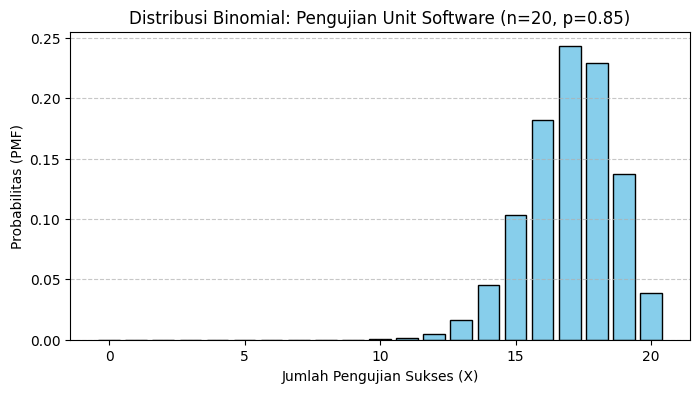

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

n, p = 20, 0.85
dist_binom = stats.binom(n, p)

# 1. Perhitungan Probabilitas
p_exact_18 = dist_binom.pmf(18)
p_at_least_15 = 1 - dist_binom.cdf(14)

# 2. Nilai Harapan dan Varians
mean, var = dist_binom.stats(moments="mv")

print(f"P(X = 18)        : {p_exact_18:.4f}")
print(f"P(X >= 15)       : {p_at_least_15:.4f}")
print(f"Nilai Harapan E(X): {mean:.2f}")
print(f"Varians Var(X)   : {var:.2f}")

# 3. Visualisasi PMF
x = np.arange(0, n + 1)
pmf_values = dist_binom.pmf(x)

plt.figure(figsize=(8, 4))
plt.bar(x, pmf_values, color="skyblue", edgecolor="black")
plt.title("Distribusi Binomial: Pengujian Unit Software (n=20, p=0.85)")
plt.xlabel("Jumlah Pengujian Sukses (X)")
plt.ylabel("Probabilitas (PMF)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

P(X = 12)       : 0.0948
P(X > 15)       : 0.0487
E(X) & Var(X)   : (np.float64(10.0), np.float64(10.0))


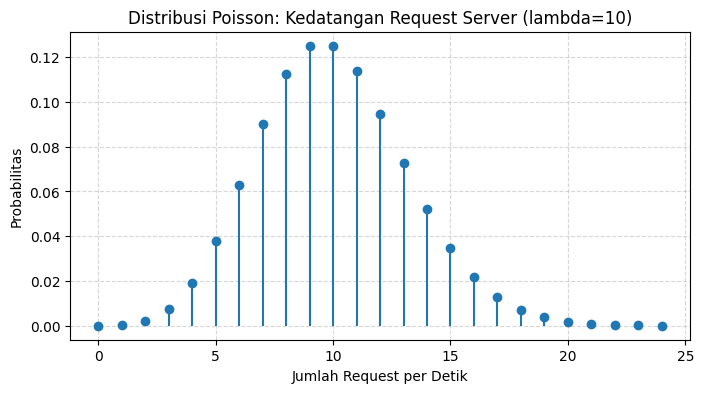

In [5]:
lambd = 10
dist_poisson = stats.poisson(lambd)

p_exact_12 = dist_poisson.pmf(12)
p_more_than_15 = 1 - dist_poisson.cdf(15)

print(f"P(X = 12)       : {p_exact_12:.4f}")
print(f"P(X > 15)       : {p_more_than_15:.4f}")
print(f"E(X) & Var(X)   : {dist_poisson.stats(moments='mv')}")

# Visualisasi
x = np.arange(0, 25)
plt.figure(figsize=(8, 4))
plt.stem(x, dist_poisson.pmf(x), basefmt=" ")
plt.title("Distribusi Poisson: Kedatangan Request Server (lambda=10)")
plt.xlabel("Jumlah Request per Detik")
plt.ylabel("Probabilitas")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

P(Server bertahan > 120 jam): 0.3012


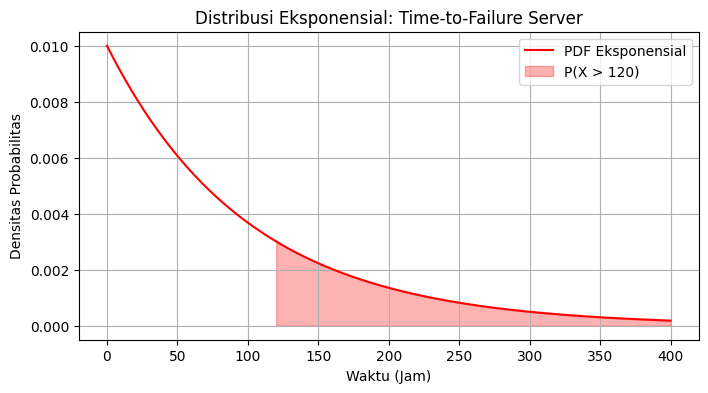

In [6]:
scale = 100  # mean (1/lambda)
dist_expon = stats.expon(scale=scale)

# P(X > 120) = 1 - P(X <= 120)
p_greater_120 = 1 - dist_expon.cdf(120)

print(f"P(Server bertahan > 120 jam): {p_greater_120:.4f}")

# Visualisasi PDF
x = np.linspace(0, 400, 1000)
pdf_values = dist_expon.pdf(x)

plt.figure(figsize=(8, 4))
plt.plot(x, pdf_values, color="red", label="PDF Eksponensial")
plt.fill_between(
    x,
    pdf_values,
    where=(x > 120),
    color="red",
    alpha=0.3,
    label="P(X > 120)",
)
plt.title("Distribusi Eksponensial: Time-to-Failure Server")
plt.xlabel("Waktu (Jam)")
plt.ylabel("Densitas Probabilitas")
plt.legend()
plt.grid(True)
plt.show()

P(45 <= X <= 55 ms): 0.6827
95th Percentile Latency: 58.22 ms


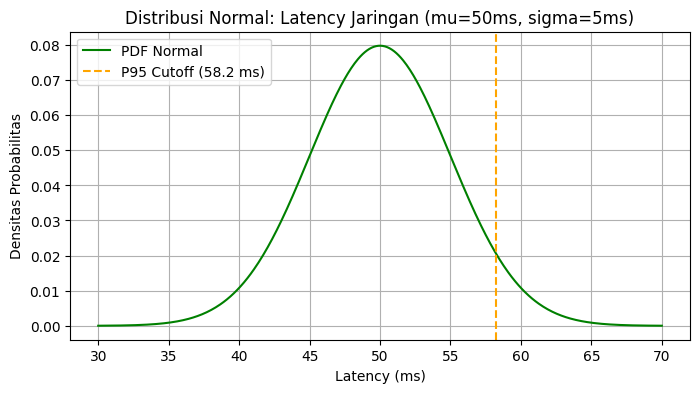

In [7]:
mu, sigma = 50, 5
dist_norm = stats.norm(loc=mu, scale=sigma)

# Probabilitas (45 <= X <= 55)
p_between = dist_norm.cdf(55) - dist_norm.cdf(45)

# P95 (SLA Latency)
p95 = dist_norm.ppf(0.95)

print(f"P(45 <= X <= 55 ms): {p_between:.4f}")
print(f"95th Percentile Latency: {p95:.2f} ms")

# Visualisasi Curve
x = np.linspace(30, 70, 500)
plt.figure(figsize=(8, 4))
plt.plot(x, dist_norm.pdf(x), label="PDF Normal", color="green")
plt.axvline(
    p95,
    color="orange",
    linestyle="--",
    label=f"P95 Cutoff ({p95:.1f} ms)",
)
plt.title("Distribusi Normal: Latency Jaringan (mu=50ms, sigma=5ms)")
plt.xlabel("Latency (ms)")
plt.ylabel("Densitas Probabilitas")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
P_pos, P_net, P_neg = 0.35, 0.45, 0.20
P_bug_given_pos = 0.05
P_bug_given_net = 0.20
P_bug_given_neg = 0.75

# Aturan Total Probabilitas
P_bug = (
    (P_bug_given_pos * P_pos)
    + (P_bug_given_net * P_net)
    + (P_bug_given_neg * P_neg)
)

print(f"Probabilitas Ulasan Mengandung Kata 'Bug': {P_bug:.4f} ({P_bug*100:.2f}%)")

Probabilitas Ulasan Mengandung Kata 'Bug': 0.2575 (25.75%)


In [9]:
import numpy as np

N_simulasi = 1_000_000
n_node = 5
p_node = 0.90

# Simulasi matriks (1,000,000 percobaan x 5 node)
status_node = np.random.rand(N_simulasi, n_node) < p_node
node_aktif_per_percobaan = np.sum(status_node, axis=1)

# Syarat klaster UP: minimal 3 node aktif
klaster_up = node_aktif_per_percobaan >= 3
p_simulasi = np.mean(klaster_up)

print(f"Hasil Simulasi Monte Carlo ({N_simulasi:,} iterasi) : {p_simulasi:.5f}")
print(f"Hasil Perhitungan Teoretis                     : 0.99144")

Hasil Simulasi Monte Carlo (1,000,000 iterasi) : 0.99142
Hasil Perhitungan Teoretis                     : 0.99144


P(Sukses tepat di percobaan ke-10): 0.0167
P(Sukses dalam <= 20 percobaan)  : 0.3324
Ekspektasi Percobaan Hingga Sukses: 50 kali


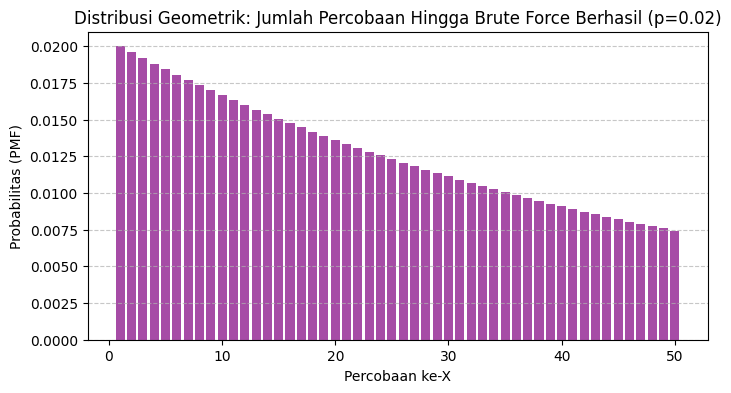

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

p = 0.02
dist_geom = stats.geom(p)

# 1. Probabilitas
p_exact_10 = dist_geom.pmf(10)
p_within_20 = dist_geom.cdf(20)
mean_trials = dist_geom.mean()

print(f"P(Sukses tepat di percobaan ke-10): {p_exact_10:.4f}")
print(f"P(Sukses dalam <= 20 percobaan)  : {p_within_20:.4f}")
print(f"Ekspektasi Percobaan Hingga Sukses: {mean_trials:.0f} kali")

# Visualisasi PMF untuk 50 percobaan pertama
x = np.arange(1, 51)
plt.figure(figsize=(8, 4))
plt.bar(x, dist_geom.pmf(x), color="purple", alpha=0.7)
plt.title("Distribusi Geometrik: Jumlah Percobaan Hingga Brute Force Berhasil (p=0.02)")
plt.xlabel("Percobaan ke-X")
plt.ylabel("Probabilitas (PMF)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

P(Tepat 2 file rentan)    : 0.3217
P(Minimal 1 file rentan)  : 0.8568


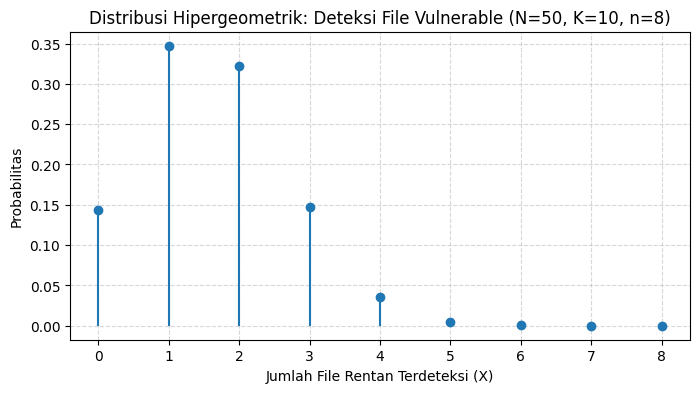

In [11]:
N = 50  # Total file
K = 10  # Total file rentan
n = 8  # Sampel yang diperiksa

dist_hyper = stats.hypergeom(M=N, n=K, N=n)

p_exact_2 = dist_hyper.pmf(2)
p_at_least_1 = 1 - dist_hyper.pmf(0)

print(f"P(Tepat 2 file rentan)    : {p_exact_2:.4f}")
print(f"P(Minimal 1 file rentan)  : {p_at_least_1:.4f}")

# Visualisasi PMF
x = np.arange(0, min(n, K) + 1)
plt.figure(figsize=(8, 4))
plt.stem(x, dist_hyper.pmf(x), basefmt=" ")
plt.title("Distribusi Hipergeometrik: Deteksi File Vulnerable (N=50, K=10, n=8)")
plt.xlabel("Jumlah File Rentan Terdeteksi (X)")
plt.ylabel("Probabilitas")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

P(Waktu Render <= 25 ms) : 0.3333
Nilai Harapan E(X)       : 30.00 ms
Varians Var(X)          : 75.00 ms^2


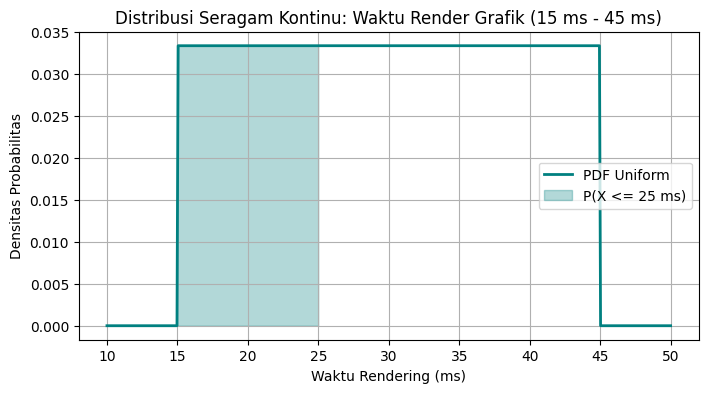

In [12]:
a, b = 15, 45
dist_uniform = stats.uniform(loc=a, scale=b - a)

p_less_25 = dist_uniform.cdf(25)
mean, var = dist_uniform.stats(moments="mv")

print(f"P(Waktu Render <= 25 ms) : {p_less_25:.4f}")
print(f"Nilai Harapan E(X)       : {mean:.2f} ms")
print(f"Varians Var(X)          : {var:.2f} ms^2")

# Visualisasi PDF
x = np.linspace(10, 50, 500)
plt.figure(figsize=(8, 4))
plt.plot(x, dist_uniform.pdf(x), color="teal", lw=2, label="PDF Uniform")
plt.fill_between(
    x,
    dist_uniform.pdf(x),
    where=(x <= 25),
    color="teal",
    alpha=0.3,
    label="P(X <= 25 ms)",
)
plt.title("Distribusi Seragam Kontinu: Waktu Render Grafik (15 ms - 45 ms)")
plt.xlabel("Waktu Rendering (ms)")
plt.ylabel("Densitas Probabilitas")
plt.legend()
plt.grid(True)
plt.show()

P(Waktu Pemrosesan > 40 detik): 0.2381


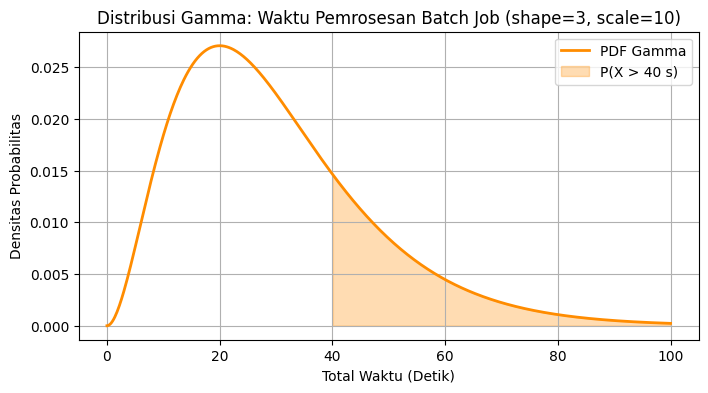

In [13]:
alpha = 3  # Shape parameter (banyaknya tahap)
beta = 10  # Scale parameter (rata-rata waktu per tahap)

dist_gamma = stats.gamma(a=alpha, scale=beta)

# P(X > 40) = 1 - P(X <= 40)
p_greater_40 = 1 - dist_gamma.cdf(40)

print(f"P(Waktu Pemrosesan > 40 detik): {p_greater_40:.4f}")

# Visualisasi PDF
x = np.linspace(0, 100, 500)
plt.figure(figsize=(8, 4))
plt.plot(x, dist_gamma.pdf(x), color="darkorange", lw=2, label="PDF Gamma")
plt.fill_between(
    x,
    dist_gamma.pdf(x),
    where=(x > 40),
    color="darkorange",
    alpha=0.3,
    label="P(X > 40 s)",
)
plt.title("Distribusi Gamma: Waktu Pemrosesan Batch Job (shape=3, scale=10)")
plt.xlabel("Total Waktu (Detik)")
plt.ylabel("Densitas Probabilitas")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
import sympy as sp
from sympy.stats import Binomial, P

# Definisi Simbol & Variabel Acak
p = sp.Symbol("p", positive=True)
X = Binomial("X", 5, p)

# Perhitungan Probabilitas Simbolik Eksak
prob_symbolic = P(sp.Eq(X, 2))
print("Formula Simbolik P(X = 2) :", prob_symbolic)

# Substitusi Nilai p = 0.1
prob_numeric = prob_symbolic.subs(p, 0.1)
print("Hasil Evaluasi Numerik (p=0.1) :", float(prob_numeric))

Formula Simbolik P(X = 2) : 10*p**2*(1 - p)**3
Hasil Evaluasi Numerik (p=0.1) : 0.07290000000000002


Probabilitas Empiris Latency <= 60 ms: 0.8930 (89.30%)


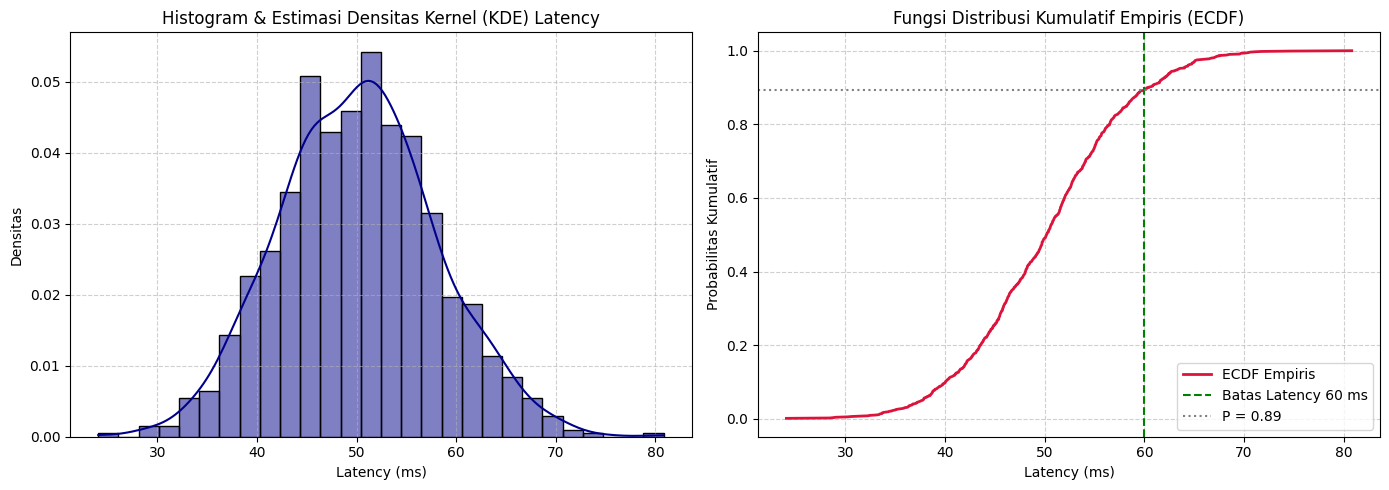

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.distributions.empirical_distribution import ECDF

# Generasi 1.000 sampel data latency sintetis (Simulasi Log Real-Time)
np.random.seed(42)
data_latency = np.random.normal(loc=50, scale=8, size=1000)

# 1. Menghitung ECDF dengan statsmodels
ecdf = ECDF(data_latency)

# Peluang latency <= 60 ms berdasarkan data sampel aktual
prob_below_60 = ecdf(60)
print(f"Probabilitas Empiris Latency <= 60 ms: {prob_below_60:.4f} ({prob_below_60*100:.2f}%)")

# 2. Visualisasi gabungan KDE Plot & ECDF dengan seaborn & matplotlib
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Estimasi Densitas Kernel (KDE)
sns.histplot(
    data_latency,
    kde=True,
    ax=axes[0],
    color="darkblue",
    stat="density",
)
axes[0].set_title("Histogram & Estimasi Densitas Kernel (KDE) Latency")
axes[0].set_xlabel("Latency (ms)")
axes[0].set_ylabel("Densitas")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot ECDF
axes[1].plot(ecdf.x, ecdf.y, color="crimson", lw=2, label="ECDF Empiris")
axes[1].axvline(60, color="green", linestyle="--", label="Batas Latency 60 ms")
axes[1].axhline(
    prob_below_60, color="gray", linestyle=":", label=f"P = {prob_below_60:.2f}"
)
axes[1].set_title("Fungsi Distribusi Kumulatif Empiris (ECDF)")
axes[1].set_xlabel("Latency (ms)")
axes[1].set_ylabel("Probabilitas Kumulatif")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()